## Lab 4.2 - Robustness, Attacks and Honest Explanations

This notebook follows Parts A-F of the lab task.  
Dataset: CICIDS2017, the same CSV files and the same cleaning as in Lab 1 (label 1 = attack, 0 = benign).  
random_state=42 is used everywhere so the numbers can be reproduced.

In [1]:
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

results_dir = Path("results")
fig_dir = Path("figures")
results_dir.mkdir(exist_ok=True)
fig_dir.mkdir(exist_ok=True)

## Setup - load and clean CICIDS2017 (same steps as Lab 1)

In [2]:
data_dir = Path("data")

# Same switch as in Lab 1. False for the final numbers, True only when testing the code quickly.
USE_SAMPLE = False
SAMPLE_FRAC = 0.25

csv_files = sorted(data_dir.glob("*.csv"))
print(f"Found {len(csv_files)} CSV files in data/")
for path in csv_files:
    print(" -", path.name)

frames = []
for csv_path in csv_files:
    try:
        frame = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        # the Thursday web attacks file has some Latin-1 bytes in it
        frame = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
        print(f"Used Latin-1 fallback for {csv_path.name}")

    # some headers have a leading space, e.g. " Label"
    frame.columns = [str(col).strip() for col in frame.columns]
    label_col = next((col for col in frame.columns if col.lower() == "label"), None)
    if frame.empty or label_col is None:
        print(f"Skipping {csv_path.name}: no usable label column")
        continue
    frames.append(frame.rename(columns={label_col: "Label"}))

df = pd.concat(frames, ignore_index=True)

# Only change from Lab 1: drop rows that have no label at all.
# Some copies of the web attacks file end with empty rows, and in Lab 1 the string "nan"
# was mapped to 1 (attack) because it is not "BENIGN".
df = df[df["Label"].notna()]

# identifiers / timestamps describe the capture, not the traffic behaviour
metadata_cols = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
df = df.drop(columns=[col for col in metadata_cols if col in df.columns])

# remove exact duplicates, and turn +-inf into NaN (they come from divisions by zero)
df = df.drop_duplicates().replace([np.inf, -np.inf], np.nan)
for col in df.columns:
    if col != "Label":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# keep the original attack names, only used in C2 to see which attack types got through
attack_names = df["Label"].astype(str).str.strip()

# binary problem: BENIGN = 0, every attack type = 1
df["Label"] = df["Label"].astype(str).str.strip().apply(lambda label: 0 if label == "BENIGN" else 1)

if USE_SAMPLE:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED)

print("\nCleaned dataset shape:", df.shape)
print(df["Label"].value_counts().sort_index())

Found 8 CSV files in data/
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv
Used Latin-1 fallback for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Cleaned dataset shape: (2813799, 81)
Label
0    2263765
1     550034
Name: count, dtype: int64


In [3]:
X = df.drop(columns=["Label"])
y = df["Label"].astype(int)

# 60/20/20 stratified split, exactly like Lab 1
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

del df, X, X_temp, y_temp   # free some memory, the full frame is big

## Part A - The baseline

### A1. Check the data is healthy

In [4]:
print("Train shape:", X_train.shape)
print("Test shape: ", X_test.shape)
print("Share of attacks in y_train:", round(y_train.mean(), 4))

# Lab 1 replaced +-inf with NaN, so the NaNs left here are mostly the old infinities.
nan_counts = X_train.isna().sum()
print("\nColumns with missing values in X_train (before fixing):")
print(nan_counts[nan_counts > 0])

# In Lab 1 the median imputer was inside each pipeline. So we run it once here to avoid having to do it again in every pipeline, and also
# because the noise / attack / SHAP steps all need a clean numeric table.
# The medians come from the training set only and are reused for val and test.
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_val = X_val.fillna(train_median)
X_test = X_test.fillna(train_median)

print("\nAll values finite?")
print("  train:", np.isfinite(X_train).all().all())
print("  val:  ", np.isfinite(X_val).all().all())
print("  test: ", np.isfinite(X_test).all().all())

# the rate columns still have some very large (but finite) values
print("\nMax of the two rate columns:")
print(X_train[["Flow Bytes/s", "Flow Packets/s"]].max())

Train shape: (1688279, 80)
Test shape:  (562760, 80)
Share of attacks in y_train: 0.1955

Columns with missing values in X_train (before fixing):
Flow Bytes/s      1685
Flow Packets/s    1685
dtype: int64

All values finite?
  train: True
  val:   True
  test:  True

Max of the two rate columns:
Flow Bytes/s      2.071000e+09
Flow Packets/s    4.000000e+06
dtype: float64


In [5]:
# continuous = more than two distinct values, flags = exactly two, constant = one value
n_unique = X_train.nunique()
continuous_cols = n_unique[n_unique > 2].index.tolist()
binary_cols = n_unique[n_unique == 2].index.tolist()
constant_cols = n_unique[n_unique <= 1].index.tolist()

print("Continuous features:", len(continuous_cols))
print("0/1 (binary) features:", len(binary_cols), binary_cols)
print("Constant features:", len(constant_cols), constant_cols)

Continuous features: 62
0/1 (binary) features: 10 ['Fwd PSH Flags', 'Fwd URG Flags', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count']
Constant features: 8 ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


### A2. Score the three models and the model that does nothing

`report()` from Lab 4.1 with PR-AUC added. I round to 4 decimals instead of 3, because on CICIDS most scores are 0.99-something and 3 decimals hide the differences.

In [6]:
def report(model, X_data, y_data):
    pred = model.predict(X_data)
    prob = model.predict_proba(X_data)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_data, pred, labels=[0, 1]).ravel()

    scores = {
        "macro_F1": f1_score(y_data, pred, average="macro"),
        "recall": recall_score(y_data, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_data, prob),
        "PR_AUC": average_precision_score(y_data, prob),
        "FAR": fp / (fp + tn),
    }
    return {name: round(float(value), 4) for name, value in scores.items()}

In [7]:
# ----- Decision tree -----
# depth picked on validation macro-F1 (like Lab 4.1, but CICIDS needs deeper trees than the phishing data)
best_score = -1
tree = None
for depth in [4, 8, 16]:
    candidate = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=SEED)
    candidate.fit(X_train, y_train)
    score = report(candidate, X_val, y_val)["macro_F1"]
    print("tree depth", depth, "validation macro-F1:", score)
    if score > best_score:
        best_score = score
        tree = candidate
print("Kept tree depth:", tree.get_depth())

# ----- Logistic regression -----
# same settings as Lab 1, scaler inside the pipeline so it is fitted on train only
logreg = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
])
logreg.fit(X_train, y_train)
print("\nLogistic regression (val):", report(logreg, X_val, y_val))

# ----- Random forest, 300 trees -----
# not wrapped in a pipeline this time, so TreeExplainer can read it directly
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
print("Random forest (val):", report(rf, X_val, y_val))

tree depth 4 validation macro-F1: 0.8365
tree depth 8 validation macro-F1: 0.9615
tree depth 16 validation macro-F1: 0.9959
Kept tree depth: 16

Logistic regression (val): {'macro_F1': 0.8855, 'recall': 0.9663, 'ROC_AUC': 0.9799, 'PR_AUC': 0.9223, 'FAR': 0.0924}
Random forest (val): {'macro_F1': 0.9993, 'recall': 0.9993, 'ROC_AUC': 1.0, 'PR_AUC': 0.9999, 'FAR': 0.0004}


In [8]:
models = {"tree": tree, "logreg": logreg, "forest": rf}

# the model that answers "benign" every time
always_benign = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train)

clean_results = {}
accuracies = {}
for name, model in {**models, "always benign": always_benign}.items():
    clean_results[name] = report(model, X_test, y_test)
    accuracies[name] = round(accuracy_score(y_test, model.predict(X_test)), 4)

clean_table = pd.DataFrame(clean_results).T
clean_table["accuracy"] = pd.Series(accuracies)
display(clean_table)
clean_table.to_csv(results_dir / "A2_clean_baseline.csv")

benign_acc = 1 - y_test.mean()
print("Always-benign accuracy = 1 - y_test.mean() =", round(benign_acc, 4), "  recall = 0")
print("Forest accuracy above always-benign:", round(accuracies["forest"] - benign_acc, 4))
print("Forest recall above always-benign:  ", clean_results["forest"]["recall"])

,macro_F1,recall,ROC_AUC,PR_AUC,FAR,accuracy
tree,0.9958,0.9995,0.9989,0.9922,0.0031,0.9974
logreg,0.8860,0.9670,0.9799,0.9212,0.0922,0.9194
forest,0.9993,0.9993,1.0000,0.9999,0.0004,0.9996
always benign,0.4458,0.0000,0.5000,0.1955,0.0000,0.8045


Always-benign accuracy = 1 - y_test.mean() = 0.8045   recall = 0
Forest accuracy above always-benign: 0.1951
Forest recall above always-benign:   0.9993


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">How far above the always-benign accuracy is your forest? Is that margin as impressive as the raw accuracy made it look?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The always-benign model already gets an accuracy of 0.8045 (1 minus the attack share of 0.1955) with recall 0. The forest gets 0.9996, so the real margin is 0.1951 and not the 0.9996 it looks like at first. Attacks are about 1 in 5 flows in our split, not 2 in 100 like the example in the lab, so the trivial baseline is lower than in the lab text, but the point is the same: about 80 of the 99.96 accuracy points come from just answering benign. The real improvement is in recall, which goes from 0 to 0.9993, and macro-F1, which goes from 0.4458 to 0.9993.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Compare ROC-AUC with PR-AUC for the same model. Which one moved more, and why?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">From always-benign to the forest, ROC-AUC went from 0.5 to 1.0000 (+0.50) and PR-AUC from 0.1955 to 0.9999 (+0.80), so PR-AUC moved more. Its starting point is the attack share and not 0.5, so it has more room to show what the model adds. The difference is clearer for logistic regression: ROC-AUC 0.9799 looks very good, but PR-AUC is only 0.9212, because it has a FAR of 0.0922. ROC-AUC uses the false positive rate, which divides the false alarms by the ~450,000 benign test flows, so even 9% false alarms look small. PR-AUC uses precision, which drops as soon as false alarms start to outnumber the real attacks found, so it is the stricter metric on imbalanced data.</p>

## Part B - Break the data by accident

### B1. Add noise

In [9]:
def add_noise(X_data, X_ref, level, seed=SEED, clip=True, cols=None):
    # Gaussian noise on the continuous columns only, the 0/1 flags are left alone.
    # Noise width for a column = level * std of that column in X_ref.
    # X_ref is always the training set (using the test set std would be leakage).
    cols = continuous_cols if cols is None else cols
    noisy = X_data.copy()
    if level == 0:
        return noisy

    rng = np.random.default_rng(seed)
    std = X_ref[cols].std().to_numpy()
    noise = rng.normal(0.0, 1.0, size=(len(noisy), len(cols))) * (level * std)
    values = noisy[cols].to_numpy(dtype=float) + noise

    if clip:
        # Durations, counts and byte totals can't be negative in a real flow, so I clip.
        # I clip at the smallest value seen in training instead of at 0: that is 0 for almost
        # every column, but Init_Win_bytes uses -1 for "not set" and clip(0) would change those too.
        values = np.maximum(values, X_ref[cols].min().to_numpy())

    noisy[cols] = values
    return noisy

level 0.00 done (3s)
level 0.05 done (4s)
level 0.10 done (4s)
level 0.20 done (4s)
level 0.50 done (4s)

Macro-F1 under noise (clipped):


level,0.00,0.05,0.10,0.20,0.50
model,,,,,
forest,0.9993,0.4465,0.4462,0.4459,0.4459
logreg,0.8860,0.8329,0.7706,0.6790,0.5743
tree,0.9958,0.5803,0.5659,0.5529,0.5438


Recall under noise (clipped):


level,0.00,0.05,0.10,0.20,0.50
model,,,,,
forest,0.9993,0.0007,0.0003,0.0001,0.0001
logreg,0.9670,0.8601,0.7836,0.7089,0.6187
tree,0.9995,0.2523,0.2370,0.2028,0.1790


All metrics at 5% noise:


,macro_F1,recall,ROC_AUC,PR_AUC,FAR
tree,0.5803,0.2523,0.5776,0.2372,0.1058
logreg,0.8329,0.8601,0.9554,0.8573,0.1116
forest,0.4465,0.0007,0.8604,0.6050,0.0000


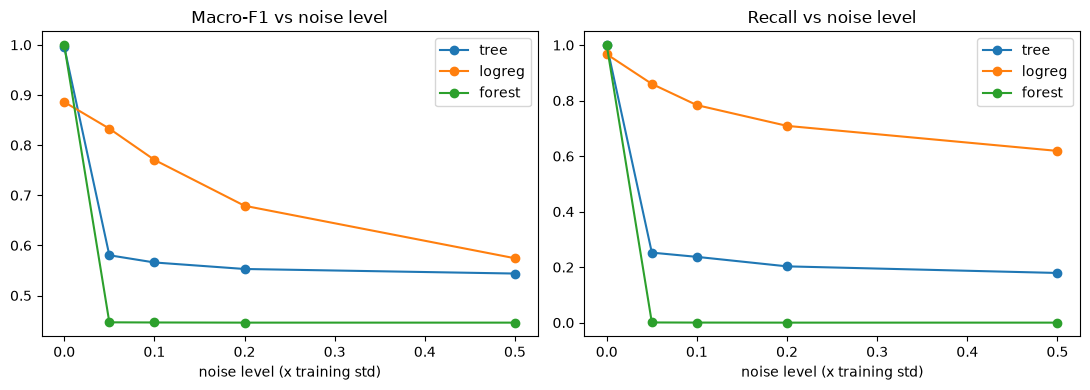

In [10]:
levels = [0.00, 0.05, 0.10, 0.20, 0.50]

noise_reports = {}   # (model, level) -> report dict, reused in Part E
for level in levels:
    t0 = time.time()
    X_noisy = add_noise(X_test, X_train, level, seed=SEED)
    for name, model in models.items():
        noise_reports[(name, level)] = report(model, X_noisy, y_test)
    print(f"level {level:.2f} done ({time.time() - t0:.0f}s)")

noise_long = pd.DataFrame([{"model": m, "level": lv, **r} for (m, lv), r in noise_reports.items()])
noise_f1 = noise_long.pivot(index="model", columns="level", values="macro_F1")
noise_recall = noise_long.pivot(index="model", columns="level", values="recall")

print("\nMacro-F1 under noise (clipped):")
display(noise_f1)
print("Recall under noise (clipped):")
display(noise_recall)
noise_long.to_csv(results_dir / "B1_noise.csv", index=False)

# all metrics at 5%, since the lab asks to always report macro-F1, recall, PR-AUC and FAR
print("All metrics at 5% noise:")
display(pd.DataFrame({name: noise_reports[(name, 0.05)] for name in models}).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in models:
    axes[0].plot(levels, noise_f1.loc[name], marker="o", label=name)
    axes[1].plot(levels, noise_recall.loc[name], marker="o", label=name)
axes[0].set_title("Macro-F1 vs noise level")
axes[1].set_title("Recall vs noise level")
for ax in axes:
    ax.set_xlabel("noise level (x training std)")
    ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "B1_noise.png", dpi=150)
plt.show()

In [11]:
# Does clipping matter? Same levels without the clip, for comparison.
clip_rows = []
for level in [0.05, 0.20, 0.50]:
    X_unclipped = add_noise(X_test, X_train, level, seed=SEED, clip=False)
    below = (X_unclipped[continuous_cols] < X_train[continuous_cols].min()).to_numpy().mean()
    for name, model in models.items():
        r = report(model, X_unclipped, y_test)
        clip_rows.append({
            "model": name, "level": level,
            "F1 clipped": noise_reports[(name, level)]["macro_F1"], "F1 not clipped": r["macro_F1"],
            "recall clipped": noise_reports[(name, level)]["recall"], "recall not clipped": r["recall"],
        })
    print(f"level {level:.2f}: {below:.1%} of the noisy continuous values fell below the training minimum")

clip_table = pd.DataFrame(clip_rows).set_index(["model", "level"])
display(clip_table)
clip_table.to_csv(results_dir / "B1_clipping.csv")
del X_unclipped

level 0.05: 31.0% of the noisy continuous values fell below the training minimum
level 0.20: 34.3% of the noisy continuous values fell below the training minimum
level 0.50: 36.7% of the noisy continuous values fell below the training minimum


,,F1 clipped,F1 not clipped,recall clipped,recall not clipped
model,level,,,,
tree,0.05,0.5803,0.5803,0.2523,0.2523
logreg,0.05,0.8329,0.8032,0.8601,0.8259
forest,0.05,0.4465,0.4465,0.0007,0.0007
tree,0.20,0.5529,0.5529,0.2028,0.2028
logreg,0.20,0.6790,0.6255,0.7089,0.7089
forest,0.20,0.4459,0.4459,0.0001,0.0001
tree,0.50,0.5438,0.5438,0.1790,0.1790
logreg,0.50,0.5743,0.5390,0.6187,0.6342
forest,0.50,0.4459,0.4459,0.0001,0.0001


The forest losing almost all of its recall at only 5% noise is the opposite of what the lab text expects, so before answering the questions I check where it comes from. Two tests on a 100,000-flow stratified sample of the test set:
1. noise on **one** continuous feature at a time (5%), to see which single features break the forest,
2. noise on all continuous features **except** Source Port, Destination Port and Protocol. These are identifiers that a sensor does not "measure", so noise on them is a bit artificial.

In [12]:
X_diag, _, y_diag, _ = train_test_split(X_test, y_test, train_size=min(100_000, len(X_test) - 2), stratify=y_test, random_state=SEED)
diag_clean_recall = recall_score(y_diag, rf.predict(X_diag))
print("Forest recall on the sample, clean:", round(diag_clean_recall, 4))

rng_diag = np.random.default_rng(SEED)
diag_rows = []
for col in continuous_cols:
    X_one = X_diag.copy()
    width = 0.05 * X_train[col].std()
    vals = X_one[col].to_numpy(dtype=float) + rng_diag.normal(0.0, width, len(X_one))
    X_one[col] = np.maximum(vals, X_train[col].min())      # same clipping as add_noise
    diag_rows.append({
        "feature": col,
        "noise width": round(width, 2),
        "share of zeros (test)": round((X_diag[col] == 0).mean(), 3),
        "forest recall": round(recall_score(y_diag, rf.predict(X_one)), 4),
    })

diag_table = pd.DataFrame(diag_rows).sort_values("forest recall").reset_index(drop=True)
print("\n10 features that hurt the forest most when ONLY they get 5% noise:")
display(diag_table.head(10))
diag_table.to_csv(results_dir / "B1_noise_per_feature.csv", index=False)

# all continuous features except the identifier columns
id_cols = [c for c in ["Source Port", "Destination Port", "Protocol"] if c in continuous_cols]
no_id_cols = [c for c in continuous_cols if c not in id_cols]
X_no_id = add_noise(X_diag, X_train, 0.05, seed=SEED, cols=no_id_cols)
X_all = add_noise(X_diag, X_train, 0.05, seed=SEED)
print("Forest recall, 5% noise on all continuous features:   ", round(recall_score(y_diag, rf.predict(X_all)), 4))
print("Forest recall, 5% noise without ports and protocol:   ", round(recall_score(y_diag, rf.predict(X_no_id)), 4))
del X_one, X_no_id, X_all

Forest recall on the sample, clean: 0.9996

10 features that hurt the forest most when ONLY they get 5% noise:


,feature,noise width,share of zeros (test),forest recall
0,Destination Port,916.07,0.000,0.8986
1,Init_Win_bytes_forward,718.88,0.035,0.9410
2,Source Port,1112.48,0.000,0.9975
3,Fwd IAT Min,431370.17,0.265,0.9984
4,Init_Win_bytes_backward,423.32,0.097,0.9985
5,Fwd Header Length,284396.35,0.000,0.9986
6,Fwd Header Length.1,284396.35,0.000,0.9988
7,Subflow Bwd Bytes,111903.59,0.248,0.9993
8,Flow IAT Std,403630.22,0.351,0.9993
9,min_seg_size_forward,51925.99,0.001,0.9994


Forest recall, 5% noise on all continuous features:    0.0009
Forest recall, 5% noise without ports and protocol:    0.0015


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Why does a single tree fall apart faster than a forest of 300 trees?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">In our run it was the other way round. At 5% noise the forest's macro-F1 fell from 0.9993 to 0.4465 and its recall from 0.9993 to 0.0007, so it calls almost every flow benign. The depth-16 tree fell to 0.5803 / 0.2523, and logistic regression held up best (0.8329 / 0.8601). After 5% the forest and tree curves are flat, they had already collapsed. <br><br>Normally a forest is more robust: one tree decides with one chain of hard thresholds, so if noise pushes a value across a split the flow can end in a completely different leaf. The forest averages 300 trees trained on different bootstrap samples and feature subsets, so their thresholds sit in slightly different places and random errors cancel out in the vote. <br><br>That only works when the trees' errors are independent, and here they are not. The noise width is 5% of a standard deviation that is dominated by a few huge flows, and many values are exactly 0 (31% of the noisy values hit the clipping limit). So for about half of the zero values the noise turns a 0 into a large positive number. That is a systematic shift towards benign-looking traffic, not small random jitter, and all 300 trees learned similar thresholds near zero, so they all make the same mistake and averaging cannot cancel it. The per-feature test shows the single feature that hurts most is Destination Port (forest recall 0.8986 when only this feature gets noise), and without noise on ports and protocol the forest recall at 5% is 0.0015 on the 100,000-flow diagnostic sample. So the forest's very high clean score depends on exact values that a real sensor would not give it.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Did clipping at zero change your results? Is a negative packet count a fair test of a model?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">I clipped at the training minimum instead of exactly 0 (see the comment in add_noise). At 5% noise 31% of the noisy values fell below that minimum, and 37% at 50%. For the tree and the forest clipping changed nothing at all, at every level. That is expected: a tree threshold always lies between two training values, so it is above the training minimum, and a value clipped to the minimum goes down the same branch of every split as a value below it. Only logistic regression changed (macro-F1 0.8329 clipped vs 0.8032 not clipped at 5%, 0.5743 vs 0.5390 at 50%), because it is linear and a negative count pushes its score further than the sensor ever could. A negative packet count or duration is not a fair test, the sensor can never produce it, so I use the clipped numbers as the main result.</p>

### B2. Lose some features

In [13]:
def drop_values(X_data, frac, seed=SEED):
    # Simulates a collector that drops fields: in every row a random `frac` of the
    # values is replaced with the training median (train_median from A1).
    values = X_data.to_numpy(dtype=float, copy=True)
    n_rows, n_cols = values.shape
    k = int(round(frac * n_cols))
    if k == 0:
        return X_data.copy()

    rng = np.random.default_rng(seed)
    # exactly k random columns per row (argpartition of random numbers = random pick without repeats)
    picked = np.argpartition(rng.random((n_rows, n_cols), dtype=np.float32), k, axis=1)[:, :k]
    med = train_median.reindex(X_data.columns).to_numpy(dtype=float)

    rows = np.repeat(np.arange(n_rows), k)
    cols = picked.ravel()
    values[rows, cols] = med[cols]
    return pd.DataFrame(values, index=X_data.index, columns=X_data.columns)

In [14]:
X_missing_10 = drop_values(X_test, 0.10, seed=SEED)

missing_reports = {name: report(model, X_missing_10, y_test) for name, model in models.items()}

missing_rows = []
for name in models:
    missing_rows.append({
        "model": name,
        "F1 clean": clean_results[name]["macro_F1"],
        "F1 5% noise": noise_reports[(name, 0.05)]["macro_F1"],
        "F1 10% missing": missing_reports[name]["macro_F1"],
        "recall clean": clean_results[name]["recall"],
        "recall 5% noise": noise_reports[(name, 0.05)]["recall"],
        "recall 10% missing": missing_reports[name]["recall"],
        "FAR 10% missing": missing_reports[name]["FAR"],
    })
missing_table = pd.DataFrame(missing_rows).set_index("model")
display(missing_table)
missing_table.to_csv(results_dir / "B2_missing.csv")

,F1 clean,F1 5% noise,F1 10% missing,recall clean,recall 5% noise,recall 10% missing,FAR 10% missing
model,,,,,,,
tree,0.9958,0.5803,0.9218,0.9995,0.2523,0.9493,0.0525
logreg,0.8860,0.8329,0.7099,0.9670,0.8601,0.7696,0.2235
forest,0.9993,0.4465,0.9894,0.9993,0.0007,0.9690,0.0007


Extra test for the second question: in a real collector a whole group of fields fails at once. I set every backward-direction feature to the training median, and separately every Idle/Active timer.

In [15]:
backward_cols = [c for c in X_test.columns if "bwd" in c.lower() or "backward" in c.lower()]
timer_cols = [c for c in X_test.columns if "idle" in c.lower() or "active" in c.lower()]
print(len(backward_cols), "backward columns,", len(timer_cols), "idle/active columns")

group_rows = []
for group_name, cols in [("all backward fields", backward_cols), ("all idle/active timers", timer_cols)]:
    X_group_lost = X_test.copy()
    X_group_lost[cols] = train_median[cols].to_numpy()
    for name, model in models.items():
        r = report(model, X_group_lost, y_test)
        group_rows.append({"lost group": group_name, "model": name, "macro_F1": r["macro_F1"],
                           "recall": r["recall"], "FAR": r["FAR"]})
del X_group_lost

group_loss_table = pd.DataFrame(group_rows).set_index(["lost group", "model"])
display(group_loss_table)
group_loss_table.to_csv(results_dir / "B2_group_loss.csv")

22 backward columns, 8 idle/active columns


macro_F1  recall     FAR
lost group             model                           
all backward fields    tree      0.6021  0.8638  0.4169
                       logreg    0.7115  0.6047  0.1468
                       forest    0.4550  0.0088  0.0000
all idle/active timers tree      0.9957  0.9994  0.0032
                       logreg    0.8681  0.9058  0.0907
                       forest    0.9979  0.9949  0.0004

### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Which does more damage, noise or missing values?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">For the two tree models, noise is far worse. With 5% noise vs 10% missing values the tree's macro-F1 is 0.5803 vs 0.9218 and the forest's 0.4465 vs 0.9894 (forest recall 0.0007 vs 0.9690). For logistic regression it is the other way round: 0.8329 with noise vs 0.7099 with missing values, mainly because its FAR jumped to 0.2235. The median is an ordinary value the trees have seen many times, so they just fall back on the other features. Noise creates values that look like a different kind of traffic. Logistic regression adds up all features linearly, so moving 8 of a flow's values to the median shifts every flow's score, and with a FAR of 0.09 already on clean data it had no margin to spare.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">In a real collector, features do not go missing one at a time. A whole group fails together, such as every backward-direction field, or every idle timer. Would that be worse than what you simulated?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">It depends strongly on which group fails. Setting all 22 backward fields to the median dropped the forest to macro-F1 0.4550 and recall 0.0088, almost the same collapse as 5% noise, while 10% random missing values only cost it 0.0099 macro-F1. The tree fell to 0.6021 with a FAR of 0.4169. With random missing values a twin from the same group usually survives and covers for the lost feature. When the whole backward group fails together there is nothing left to cover for it. Losing all 8 idle/active timers did almost nothing (forest 0.9979 macro-F1, recall 0.9949). These timers are 0 for most flows, and their information overlaps with Flow IAT Max and Fwd IAT Max, which end up in the same correlation group in E2. So yes, a group failure can be much worse than what we simulated, but only for groups the model really depends on.</p>

## Part C - Break the model on purpose

### C1. Sort the features and set a budget

Sorted by name pattern, following Section 3.4. If I was not sure about a feature it goes to Fixed.

In [16]:
# features that mix both directions, or that the target / network decides
BOTH_DIRECTIONS = ["Flow Bytes/s", "Flow Packets/s", "Min Packet Length", "Max Packet Length",
                   "Packet Length Mean", "Packet Length Std", "Packet Length Variance",
                   "Average Packet Size", "Down/Up Ratio"]

def feature_group(name):
    low = name.lower()
    # 1) backward direction = produced by the victim's stack -> Fixed.
    #    Checked first, so "Bwd IAT ..." ends up Fixed and not Free.
    if "bwd" in low or "backward" in low:
        return "Fixed"
    # 2) port / protocol, flag counts (both directions, partly set by the responder;
    #    Fwd PSH/URG Flags are 0/1 columns so a "half std" increase is not a real change),
    #    and statistics computed over both directions
    if name in ["Destination Port", "Protocol"] or "flag" in low or name in BOTH_DIRECTIONS:
        return "Fixed"
    # 3) timing: waiting longer costs the attacker nothing
    if "iat" in low or "idle" in low or "active" in low or name == "Flow Duration":
        return "Free"
    # 4) forward sizes / headers: padding is cheap.
    #    Init_Win_bytes_forward is the attacker's own TCP window and Source Port is picked by the
    #    attacker's OS, so both are under their control (they are not in the lab list, my own decision).
    if (name.startswith("Fwd Packet Length") or name.startswith("Fwd Header Length")
            or name in ["Avg Fwd Segment Size", "min_seg_size_forward", "Init_Win_bytes_forward", "Source Port"]):
        return "Free"
    # 5) more forward packets / bytes: possible, but more work and a louder attack
    if (name in ["Total Fwd Packets", "Total Length of Fwd Packets", "act_data_pkt_fwd", "Fwd Packets/s"]
            or name.startswith("Subflow Fwd") or name.startswith("Fwd Avg")):
        return "Costly"
    # not sure -> Fixed, a weaker attacker is the safer mistake
    return "Fixed"


# If the constrained attack evades nothing at all, move a few Fixed features here and say so in the report.
EXTRA_COSTLY = []

groups = pd.Series({f: ("Costly" if f in EXTRA_COSTLY else feature_group(f)) for f in X_train.columns})
print(groups.value_counts(), "\n")
for g in ["Free", "Costly", "Fixed"]:
    print(f"{g}: {groups[groups == g].index.tolist()}\n")

groups.rename("group").to_csv(results_dir / "C1_feature_groups.csv")

Fixed     43
Free      28
Costly     9
Name: count, dtype: int64 

Free: ['Source Port', 'Flow Duration', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Fwd Header Length', 'Avg Fwd Segment Size', 'Fwd Header Length.1', 'Init_Win_bytes_forward', 'min_seg_size_forward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

Costly: ['Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packets/s', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'act_data_pkt_fwd']

Fixed: ['Destination Port', 'Protocol', 'Total Backward Packets', 'Total Length of Bwd Packets', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', '

In [17]:
def can_change(feature, old_value, new_value):
    # only Free / Costly features, and only upwards (the attacker can add and wait, not remove)
    return groups[feature] in ("Free", "Costly") and new_value >= old_value


# budget
STEP_FRAC = 0.5      # one step can raise a feature by at most half of its training std
MAX_FEATURES = 5     # at most 5 different features changed per flow
N_STEPS = 5          # greedy search length

train_std = X_train.std()
step_size = train_std * STEP_FRAC
feature_list = list(X_train.columns)

### C2. Run the attack, twice

Greedy search: in each of the 5 steps every allowed change is tried and the one that lowers the attack probability the most is kept.  
In the constrained run each candidate is a +0.5 std increase that has to pass `can_change` and the 5-feature budget.  
In the unconstrained run every feature can move +0.5 std or -0.5 std, with no group or direction rules. The step size and number of steps stay the same, so the only difference between the two runs is the constraints.

Two choices I made that the lab text leaves open:
- Each candidate uses the **largest** allowed step (half a std) instead of trying several smaller amounts too.
- The search also stops as soon as the flow drops below 0.5, since a real attacker would stop once they get through. This cannot change how many flows evade (an accepted step only ever lowers the probability), it only means "mean p after" and "features changed" describe the cheapest way through.
- The unconstrained run still keeps the 0.5 std step and 5 steps. It already evaded 50 of 50, so removing that limit as well could not raise the count.

In [18]:
def greedy_attack(model, row, constrained=True):
    x = row.to_numpy(dtype=float).copy()      # work on a copy, never on the test set itself
    p_start = model.predict_proba(pd.DataFrame([x], columns=feature_list))[0, 1]
    p_now = p_start
    changed = []                               # one entry per step that was kept

    for step in range(N_STEPS):
        cand_rows, cand_feats = [], []
        for j, f in enumerate(feature_list):
            if step_size[f] == 0:
                continue                       # constant column, nothing to move
            deltas = [step_size[f]] if constrained else [step_size[f], -step_size[f]]
            for delta in deltas:
                new_value = x[j] + delta
                if constrained:
                    if not can_change(f, x[j], new_value):
                        continue
                    if f not in changed and len(set(changed)) >= MAX_FEATURES:
                        continue
                cand = x.copy()
                cand[j] = new_value
                cand_rows.append(cand)
                cand_feats.append(f)

        if not cand_rows:
            break
        # score all candidates in one call (much faster than one call per candidate)
        probs = model.predict_proba(pd.DataFrame(cand_rows, columns=feature_list))[:, 1]
        best = int(np.argmin(probs))
        if probs[best] >= p_now:
            break                              # nothing helps any more -> stop early
        x, p_now = cand_rows[best], probs[best]
        changed.append(cand_feats[best])
        if p_now < 0.5:
            break                              # flow is now called benign, the attacker can stop

    return x, p_start, p_now, changed


def run_attack(model, rows, constrained=True):
    adv_rows, summary, all_changes = [], [], []
    for idx, row in rows.iterrows():
        x_adv, p0, p1, changed = greedy_attack(model, row, constrained)
        adv_rows.append(x_adv)
        all_changes.extend(changed)
        summary.append({"p_before": p0, "p_after": p1, "evaded": p1 < 0.5, "n_features": len(set(changed)),
                        "changed": ", ".join(dict.fromkeys(changed))})
    adv = pd.DataFrame(adv_rows, index=rows.index, columns=feature_list)
    return adv, pd.DataFrame(summary, index=rows.index), all_changes

In [19]:
# 50 test flows the forest is most sure are attacks. I also require that they really are attacks,
# so these are correctly detected attack flows (they are reused in Part F1).
p_test_rf = rf.predict_proba(X_test)[:, 1]
attack_pos = np.where((y_test.to_numpy() == 1) & (p_test_rf >= 0.5))[0]
top50_pos = attack_pos[np.argsort(-p_test_rf[attack_pos], kind="stable")[:50]]
X50 = X_test.iloc[top50_pos]
print("Attack probability of the chosen 50: min", p_test_rf[top50_pos].min().round(4),
      " max", p_test_rf[top50_pos].max().round(4))

t0 = time.time()
adv_con, sum_con, changes_con = run_attack(rf, X50, constrained=True)
print(f"constrained attack done ({time.time() - t0:.0f}s)")
t0 = time.time()
adv_free, sum_free, changes_free = run_attack(rf, X50, constrained=False)
print(f"unconstrained attack done ({time.time() - t0:.0f}s)")


def attack_summary(s):
    return {"evaded (of 50)": int(s["evaded"].sum()),
            "mean p before": round(s["p_before"].mean(), 4),
            "mean p after": round(s["p_after"].mean(), 4),
            "mean features changed": round(s["n_features"].mean(), 2)}

attack_table = pd.DataFrame({"constrained": attack_summary(sum_con),
                             "unconstrained": attack_summary(sum_free)})
display(attack_table)
attack_table.to_csv(results_dir / "C2_attack.csv")

Attack probability of the chosen 50: min 1.0  max 1.0
constrained attack done (7s)
unconstrained attack done (4s)


,constrained,unconstrained
evaded (of 50),22.0000,50.0000
mean p before,1.0000,1.0000
mean p after,0.5863,0.3997
mean features changed,4.1400,1.9400


The lab says the flows that still get through the constrained attack are the ones worth looking at, so here they are with their original attack type.

In [20]:
look = sum_con.copy()
look["attack type"] = attack_names.loc[X50.index].to_numpy()

print("Attack types among the 50 chosen flows:")
print(look["attack type"].value_counts())

print("\nEvaded vs not evaded, per attack type:")
display(pd.crosstab(look["attack type"], look["evaded"]))

print("Evaded flows and what the attacker changed:")
display(look[look["evaded"]][["attack type", "p_after", "n_features", "changed"]])
look.to_csv(results_dir / "C2_evaded_flows.csv")

Attack types among the 50 chosen flows:
attack type
DDoS             20
DoS Hulk         15
PortScan         13
DoS GoldenEye     1
FTP-Patator       1
Name: count, dtype: int64

Evaded vs not evaded, per attack type:


evaded,False,True
attack type,,
DDoS,15,5
DoS GoldenEye,1,0
DoS Hulk,12,3
FTP-Patator,0,1
PortScan,0,13


Evaded flows and what the attacker changed:


,attack type,p_after,n_features,changed
468789,PortScan,0.476667,4,"Subflow Fwd Bytes, Total Length of Fwd Packets..."
391488,PortScan,0.406667,4,"Flow IAT Min, Flow IAT Mean, Flow IAT Max, Flo..."
81109,DDoS,0.466667,2,"Init_Win_bytes_forward, Fwd IAT Min"
65655,DDoS,0.403333,2,"Init_Win_bytes_forward, Fwd IAT Min"
472256,PortScan,0.476667,4,"Subflow Fwd Bytes, Total Length of Fwd Packets..."
440289,PortScan,0.490000,3,"Flow IAT Min, Flow IAT Mean, Flow IAT Max"
430823,PortScan,0.460000,4,"Subflow Fwd Bytes, Total Length of Fwd Packets..."
371168,PortScan,0.466667,4,"Subflow Fwd Bytes, Total Length of Fwd Packets..."
394197,PortScan,0.460000,4,"Subflow Fwd Bytes, Total Length of Fwd Packets..."
2586234,DoS Hulk,0.210000,1,Init_Win_bytes_forward


In [21]:
# Sanity check on the constraints: in the constrained run no Fixed feature may change
# and nothing may go down.
diff = adv_con - X50
moved = diff.ne(0)
moved_features = moved.any()[moved.any()].index.tolist()
print("Features moved by the constrained attack:", moved_features)
assert all(groups[f] != "Fixed" for f in moved_features), "a Fixed feature was changed!"
assert (diff.to_numpy() >= 0).all(), "a feature was decreased!"
assert (moved.sum(axis=1) <= MAX_FEATURES).all(), "more than 5 features changed on a flow!"
print("Constraint check passed.")

Features moved by the constrained attack: ['Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Std', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Min', 'Fwd Header Length', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Init_Win_bytes_forward', 'act_data_pkt_fwd', 'Active Std']
Constraint check passed.


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">The gap between the two runs is protection that comes from the network, not from your model. Which of the two numbers would you quote to a customer, and which to your own security team?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The constrained attack evaded 22 of 50 flows (mean probability 1.0000 to 0.5863, 4.14 features changed) and the unconstrained one 50 of 50 (to 0.3997, only 1.94 features changed). So 28 of the 50 flows were protected only because the attacker cannot touch the features the model relies on. To a customer I would quote the constrained number, because it describes an attacker who has to obey how TCP/IP works, which is the realistic threat. It is not a flattering number either: 44% of the flows the forest was 100% sure about got through with at most five changes. To our own security team I would give both, with the unconstrained one as the worst case. The unconstrained attack mostly moved Init_Win_bytes_backward and Destination Port, so if an attacker ever gets control over the victim side (e.g. a compromised host or a middlebox that rewrites the window) that 28-flow protection is gone.</p>

### C3. See what the attack touched

In [22]:
def top_changed(change_list, n=10):
    counts = pd.Series(change_list, dtype=object).value_counts().head(n)
    return pd.DataFrame({"times changed": counts, "group": groups[counts.index]})

attack_top10 = top_changed(changes_con)
print("Constrained attack - most changed features:")
display(attack_top10)

print("Unconstrained attack - most changed features (for comparison):")
display(top_changed(changes_free))

attack_top10.to_csv(results_dir / "C3_attack_top10.csv")

Constrained attack - most changed features:


,times changed,group
act_data_pkt_fwd,27,Costly
Fwd Packet Length Min,27,Free
Subflow Fwd Packets,20,Costly
Total Fwd Packets,20,Costly
Active Std,18,Free
Total Length of Fwd Packets,16,Costly
Fwd Header Length.1,16,Free
Subflow Fwd Bytes,10,Costly
Flow IAT Min,10,Free
Init_Win_bytes_forward,10,Free


Unconstrained attack - most changed features (for comparison):


,times changed,group
Init_Win_bytes_backward,41,Fixed
Destination Port,37,Fixed
Init_Win_bytes_forward,7,Free
Bwd Header Length,6,Fixed
Subflow Fwd Bytes,6,Costly


No Fixed feature is in the constrained list (the assert in C2 checks this too).  
The lab expected timing features to lead. In our run only Flow IAT Min and Active Std are timing features. Half of the top 10 are Costly packet-count features (act_data_pkt_fwd, Total Fwd Packets, Subflow Fwd Packets, Total Length of Fwd Packets, Subflow Fwd Bytes). The most-changed list has a tie: act_data_pkt_fwd and Fwd Packet Length Min were each changed 27 times.  
The budget treats Free and Costly the same (both can rise by half a std per step), so the search has no reason to prefer the cheap changes. A version that charges more for Costly steps would probably lean more on the timers.

## Part D - Does SHAP point where the attacker goes?

### D1. Put the two lists next to each other

SHAP for 500 flows took 133s, raw shape (500, 80, 2)


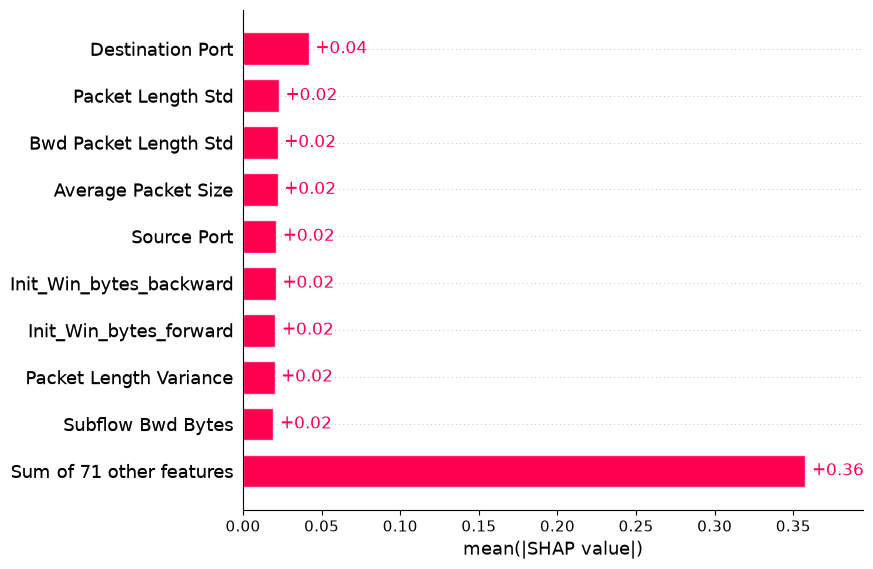

In [23]:
explainer = shap.TreeExplainer(rf)

# TreeSHAP on a 300-tree forest trained on ~1.7M flows is slow, so 500 test flows only.
# check_additivity=False because sklearn forests sometimes fail SHAP's internal check by tiny
# float32/float64 rounding; I check the additivity myself in F2.
X_shap = X_test.iloc[:500]
t0 = time.time()
sv = explainer(X_shap, check_additivity=False)
print(f"SHAP for 500 flows took {time.time() - t0:.0f}s, raw shape {sv.values.shape}")

sv1 = sv[:, :, 1]     # attack class
shap_rank = pd.Series(np.abs(sv1.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)

shap.plots.bar(sv1, max_display=10)

In [24]:
shap_top10 = shap_rank.index[:10].tolist()
attack_list = attack_top10.index.tolist()

side_by_side = pd.DataFrame({
    "SHAP top 10": shap_top10,
    "SHAP group": groups[shap_top10].tolist(),
    "mean |SHAP|": shap_rank.iloc[:10].round(4).tolist(),
    "attacker top 10": attack_list + [""] * (10 - len(attack_list)),
    "attacker group": groups[attack_list].tolist() + [""] * (10 - len(attack_list)),
})
display(side_by_side)

overlap = set(shap_top10) & set(attack_list)
print("In both lists:", len(overlap), sorted(overlap))
print("Groups in the SHAP top 10:", groups[shap_top10].value_counts().to_dict())

# where do the attacker's favourite features sit in the full SHAP ranking?
print("\nSHAP rank (1 = most important) of the attacker's features:")
print({f: int(shap_rank.index.get_loc(f)) + 1 for f in attack_list})

side_by_side.to_csv(results_dir / "D1_shap_vs_attack.csv", index=False)

,SHAP top 10,SHAP group,mean |SHAP|,attacker top 10,attacker group
0,Destination Port,Fixed,0.0418,act_data_pkt_fwd,Costly
1,Packet Length Std,Fixed,0.0228,Fwd Packet Length Min,Free
2,Bwd Packet Length Std,Fixed,0.0220,Subflow Fwd Packets,Costly
3,Average Packet Size,Fixed,0.0220,Total Fwd Packets,Costly
4,Source Port,Free,0.0211,Active Std,Free
5,Init_Win_bytes_backward,Fixed,0.0209,Total Length of Fwd Packets,Costly
6,Init_Win_bytes_forward,Free,0.0205,Fwd Header Length.1,Free
7,Packet Length Variance,Fixed,0.0200,Subflow Fwd Bytes,Costly
8,Subflow Bwd Bytes,Fixed,0.0193,Flow IAT Min,Free
9,Total Length of Bwd Packets,Fixed,0.0183,Init_Win_bytes_forward,Free


In both lists: 1 ['Init_Win_bytes_forward']
Groups in the SHAP top 10: {'Fixed': 8, 'Free': 2}

SHAP rank (1 = most important) of the attacker's features:
{'act_data_pkt_fwd': 55, 'Fwd Packet Length Min': 18, 'Subflow Fwd Packets': 41, 'Total Fwd Packets': 40, 'Active Std': 66, 'Total Length of Fwd Packets': 23, 'Fwd Header Length.1': 25, 'Subflow Fwd Bytes': 20, 'Flow IAT Min': 46, 'Init_Win_bytes_forward': 7}


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Are your model's most important features ones the attacker can change, or ones they cannot? What does your answer say about how easily this model could be evaded?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">Mostly ones they cannot. 8 of the SHAP top 10 are Fixed (Destination Port, Packet Length Std, Bwd Packet Length Std, Average Packet Size, Init_Win_bytes_backward, Packet Length Variance, Subflow Bwd Bytes and Total Length of Bwd Packets), and only 2 are Free (Source Port at rank 5 and Init_Win_bytes_forward at rank 7). Only 1 feature is in both lists, Init_Win_bytes_forward. Because most of the weight is on the destination port, the victim's replies and both-direction statistics, the attacker has to work through less important features. That fits with the constrained attack needing 4.14 changes on average and still only getting 22 of 50 through. The two Free features in the top 10 are the weak spot. Source Port is chosen by the attacker's own OS. It is probably important in CICIDS because the attack tools in the capture used particular port ranges, which is a property of this dataset rather than of real attacks. Our attack never moved it (a +0.5 std jump did not help), but an attacker who sets the port directly could.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">If a feature is used often by the attack but ranked low by SHAP, what could explain that?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">act_data_pkt_fwd was changed most often by the attack (27 times) but is only 55th in the SHAP ranking, and Active Std was used 18 times but ranked 66th. SHAP is the average over 500 ordinary test flows, and about 80% of them are benign, while the attacker only needs a feature that sits close to a split for these 50 specific attack flows. The attacker can also only pick from Free and Costly features, so it uses the best of what is allowed, not the best overall. And because of twins, SHAP may give the credit for packet counts to related features (Total Fwd Packets, Subflow Fwd Packets), even though the model reacts to act_data_pkt_fwd as well.</p>

### D2. Is the explanation stable under noise?

In [25]:
# The clean SHAP values for the first 200 flows are already in sv1 (same explainer, same rows).
X_200 = X_test.iloc[:200]
X_200_noisy = add_noise(X_200, X_train, 0.05, seed=SEED)

sv_noisy = explainer(X_200_noisy, check_additivity=False)[:, :, 1]

imp_clean = pd.Series(np.abs(sv1.values[:200]).mean(axis=0), index=X_test.columns)
imp_noisy = pd.Series(np.abs(sv_noisy.values).mean(axis=0), index=X_test.columns)

rho, p_value = spearmanr(imp_clean, imp_noisy)
print("Spearman rank correlation clean vs 5% noise:", round(rho, 3))

display(pd.DataFrame({
    "clean top 5": imp_clean.sort_values(ascending=False).index[:5],
    "5% noise top 5": imp_noisy.sort_values(ascending=False).index[:5],
}))

Spearman rank correlation clean vs 5% noise: 0.965


,clean top 5,5% noise top 5
0,Destination Port,Destination Port
1,Packet Length Std,Init_Win_bytes_backward
2,Bwd Packet Length Std,Total Length of Bwd Packets
3,Source Port,Bwd Packet Length Std
4,Average Packet Size,Source Port


Spearman 0.965 is above 0.90, so the ranking is stable. Destination Port stays first, and the rest of the top 5 reshuffles a bit (Packet Length Std and Average Packet Size drop out; Init_Win_bytes_backward and Total Length of Bwd Packets come in).

The same 5% noise destroyed the forest's recall in B1 (0.9993 to 0.0007), yet the explanation barely changed. So a stable explanation tells us nothing about whether the model is still right. Stable is not the same as faithful, which is what Part F tests.

## Part E - Two defences

### E1. An ensemble

In [26]:
# Gradient boosting in sklearn is single-threaded and very slow on 1.7M rows,
# so it is trained on a stratified 100,000-row subsample of the training set (mentioned in the report).
GB_ROWS = 100_000
if len(X_train) > GB_ROWS:
    X_gb, _, y_gb, _ = train_test_split(X_train, y_train, train_size=GB_ROWS, stratify=y_train, random_state=SEED)
else:
    X_gb, y_gb = X_train, y_train

t0 = time.time()
gb = GradientBoostingClassifier(n_estimators=200, max_depth=4, random_state=SEED)
gb.fit(X_gb, y_gb)
print(f"Gradient boosting trained on {len(X_gb)} rows in {time.time() - t0:.0f}s")
print("Gradient boosting (test):", report(gb, X_test, y_test))


class AverageEnsemble:
    # averages the attack probability of its members, so report() and the attack code still work
    def __init__(self, members):
        self.members = members

    def predict_proba(self, X_data):
        p = np.mean([m.predict_proba(X_data)[:, 1] for m in self.members], axis=0)
        return np.column_stack([1 - p, p])

    def predict(self, X_data):
        return (self.predict_proba(X_data)[:, 1] >= 0.5).astype(int)


ensemble = AverageEnsemble([rf, gb, logreg])

Gradient boosting trained on 100000 rows in 159s
Gradient boosting (test): {'macro_F1': 0.998, 'recall': 0.997, 'ROC_AUC': 0.9999, 'PR_AUC': 0.9998, 'FAR': 0.0008}


In [27]:
X_noisy_05 = add_noise(X_test, X_train, 0.05, seed=SEED)

ens_clean = report(ensemble, X_test, y_test)
ens_noise = report(ensemble, X_noisy_05, y_test)
ens_missing = report(ensemble, X_missing_10, y_test)

# Attack, two ways:
# (a) transfer: the 50 flows the attacker already crafted against the forest in C2
p_transfer = ensemble.predict_proba(adv_con)[:, 1]
# (b) adaptive: the attacker runs the same constrained greedy search against the ensemble itself
adv_ens, sum_ens, changes_ens = run_attack(ensemble, X50, constrained=True)

# all four metrics the lab asks for, forest next to ensemble
forest_rep = {"clean": clean_results["forest"], "5% noise": noise_reports[("forest", 0.05)],
              "10% missing": missing_reports["forest"]}
ens_rep = {"clean": ens_clean, "5% noise": ens_noise, "10% missing": ens_missing}
e1_rows = {}
for cond in forest_rep:
    e1_rows[cond] = {}
    for metric in ["macro_F1", "recall", "PR_AUC", "FAR"]:
        e1_rows[cond][f"forest {metric}"] = forest_rep[cond][metric]
        e1_rows[cond][f"ensemble {metric}"] = ens_rep[cond][metric]
display(pd.DataFrame(e1_rows).T)

attack_compare = pd.DataFrame({
    "forest (C2)": {"evaded (of 50)": int(sum_con["evaded"].sum()), "mean p after": round(sum_con["p_after"].mean(), 4)},
    "ensemble, transferred flows": {"evaded (of 50)": int((p_transfer < 0.5).sum()), "mean p after": round(p_transfer.mean(), 4)},
    "ensemble, adaptive attack": {"evaded (of 50)": int(sum_ens["evaded"].sum()), "mean p after": round(sum_ens["p_after"].mean(), 4)},
}).T
print("Constrained attack:")
display(attack_compare)
print("Flows the ensemble already missed before any attack:", int((sum_ens["p_before"] < 0.5).sum()))

pd.DataFrame(e1_rows).T.to_csv(results_dir / "E1_ensemble_robustness.csv")
attack_compare.to_csv(results_dir / "E1_ensemble_attack.csv")

,forest macro_F1,ensemble macro_F1,forest recall,ensemble recall,forest PR_AUC,ensemble PR_AUC,forest FAR,ensemble FAR
clean,0.9993,0.9984,0.9993,0.9986,0.9999,0.9999,0.0004,0.0009
5% noise,0.4465,0.6623,0.0007,0.2732,0.6050,0.7574,0.0000,0.0127
10% missing,0.9894,0.9848,0.9690,0.9596,0.9989,0.9888,0.0007,0.0019


Constrained attack:


,evaded (of 50),mean p after
forest (C2),22.0,0.5863
"ensemble, transferred flows",6.0,0.7687
"ensemble, adaptive attack",23.0,0.6075


Flows the ensemble already missed before any attack: 0


In [28]:
# rough latency check for the line-rate question: time to score 10,000 flows
X_lat = X_test.iloc[:10_000]
for name, model in [("forest", rf), ("ensemble", ensemble)]:
    t0 = time.time()
    model.predict_proba(X_lat)
    dt = time.time() - t0
    print(f"{name:9s}: {dt:.2f}s for 10,000 flows  ->  {dt / 10_000 * 1e6:.1f} microseconds per flow")

forest   : 0.04s for 10,000 flows  ->  4.0 microseconds per flow
ensemble : 0.06s for 10,000 flows  ->  6.3 microseconds per flow


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Did the ensemble help more against noise or against the attack? Why might those two differ?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">Against noise it helped a lot: at 5% noise the ensemble got macro-F1 0.6623 and recall 0.2732, against 0.4465 and 0.0007 for the forest, though it is still far below its clean score. On clean data and 10% missing values it was slightly worse than the forest (0.9984 vs 0.9993 and 0.9848 vs 0.9894). Against the attack it depends on the attacker. Flows crafted against the forest transfer badly: only 6 of the 50 get through the ensemble, against 22 for the forest. But an attacker who runs the same constrained search on the ensemble itself gets 23 of 50 through, practically the same as against the forest. Noise is not aimed. Logistic regression and gradient boosting react to different features and have smoother boundaries, and logistic regression was the most noise-robust model in B1, so averaging them helps. The attack is aimed: the greedy search simply looks for the change that lowers the average, so model diversity only helps against an attacker who does not know about it. The transfer number would overstate the defence.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">An intrusion detector has to answer in milliseconds at line rate. Is running three models affordable there?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">In batches of 10,000 the forest needed 4.2 µs per flow and the ensemble 6.5 µs, so about 1.5 times the cost. The extra cost is small because logistic regression is almost free and the boosting trees are only depth 4. These are batch numbers on all CPU cores, though; scoring flows one at a time costs much more per flow because of the call overhead. At around 100,000 new flows per second the ensemble would need ~0.65 s of CPU per second, so it is only affordable with batching. Since it did not help against an adaptive attacker and was slightly worse on clean data, I would rather use it as a second stage for flows the forest is unsure about than run it on everything.</p>

### E2. Drop one feature, then drop a whole group

Same subsample every time (50,000 training flows, 50,000 test flows) so the comparison is fair. 100-tree forest.

In [29]:
E2_TRAIN, E2_TEST = 50_000, 50_000
X_e2_tr, _, y_e2_tr, _ = train_test_split(X_train, y_train, train_size=min(E2_TRAIN, len(X_train) - 2),
                                          stratify=y_train, random_state=SEED)
X_e2_te, _, y_e2_te, _ = train_test_split(X_test, y_test, train_size=min(E2_TEST, len(X_test) - 2),
                                          stratify=y_test, random_state=SEED)

def small_forest_f1(drop_cols=()):
    cols = [c for c in X_e2_tr.columns if c not in set(drop_cols)]
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1)
    m.fit(X_e2_tr[cols], y_e2_tr)
    return f1_score(y_e2_te, m.predict(X_e2_te[cols]), average="macro")

base_f1 = small_forest_f1()
print("Small forest, all features, macro-F1:", round(base_f1, 5))

t0 = time.time()
single_cost = {}
for f in X_e2_tr.columns:
    single_cost[f] = base_f1 - small_forest_f1([f])
single_cost = pd.Series(single_cost).sort_values(ascending=False)
print(f"single-feature loop took {time.time() - t0:.0f}s")

print("\nFive features whose removal costs the most macro-F1:")
print(single_cost.head(5).round(5))
single_cost.to_csv(results_dir / "E2_single_removal.csv")

Small forest, all features, macro-F1: 0.99739
single-feature loop took 52s

Five features whose removal costs the most macro-F1:
Init_Win_bytes_forward    0.00114
Destination Port          0.00098
Source Port               0.00064
Fwd IAT Min               0.00054
URG Flag Count            0.00038
dtype: float64


In [30]:
# Groups of near-duplicate features: |correlation| > 0.95 on the training set.
# Pairs are joined into groups by chaining (if A~B and B~C then A, B, C are one group).
corr_abs = X_train.corr().abs()
CORR_CUT = 0.95

parent = {f: f for f in corr_abs.columns}
def find(f):
    while parent[f] != f:
        parent[f] = parent[parent[f]]
        f = parent[f]
    return f

cols = corr_abs.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if corr_abs.iloc[i, j] > CORR_CUT:      # NaN (constant columns) is never > 0.95
            parent[find(cols[i])] = find(cols[j])

corr_groups = {}
for f in cols:
    corr_groups.setdefault(find(f), []).append(f)
corr_groups = [g for g in corr_groups.values() if len(g) > 1]
print(len(corr_groups), "groups of correlated features")

t0 = time.time()
group_rows = []
for g in corr_groups:
    cost = base_f1 - small_forest_f1(g)
    group_rows.append({
        "group size": len(g),
        "group cost": round(cost, 5),
        "max single cost in group": round(single_cost[g].max(), 5),
        "features": ", ".join(g),
    })
print(f"group loop took {time.time() - t0:.0f}s")

group_table = pd.DataFrame(group_rows).sort_values("group cost", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", 120)
display(group_table)
group_table.to_csv(results_dir / "E2_group_removal.csv", index=False)

14 groups of correlated features
group loop took 9s


,group size,group cost,max single cost in group,features
0,2,0.00051,0.00029,"Total Length of Fwd Packets, Subflow Fwd Bytes"
1,2,0.00035,0.00016,"Packet Length Mean, Average Packet Size"
2,2,0.00029,0.00013,"Fwd URG Flags, CWE Flag Count"
3,2,0.00029,0.00022,"Max Packet Length, Packet Length Std"
4,2,0.00022,0.00025,"Flow Duration, Fwd IAT Total"
5,2,0.00022,0.00019,"Fwd PSH Flags, SYN Flag Count"
6,2,0.00019,0.00022,"Fwd Packet Length Max, Fwd Packet Length Std"
7,2,0.00016,0.00022,"Fwd Packet Length Mean, Avg Fwd Segment Size"
8,4,0.00016,0.00029,"Bwd Packet Length Max, Bwd Packet Length Mean, Bwd Packet Length Std, Avg Bwd Segment Size"
9,6,0.00013,0.00035,"Total Fwd Packets, Total Backward Packets, Total Length of Bwd Packets, Subflow Fwd Packets, Subflow Bwd Packets, Su..."


In [31]:
# How big is the run-to-run noise of this measurement? Same data, all features, only the forest seed changes.
# Differences between removals that are smaller than this spread can't be told apart from noise.
seed_f1 = []
for s in range(5):
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=s, n_jobs=-1)
    m.fit(X_e2_tr, y_e2_tr)
    seed_f1.append(f1_score(y_e2_te, m.predict(X_e2_te), average="macro"))
seed_f1 = np.array(seed_f1)
print("Macro-F1 over 5 seeds:", seed_f1.round(5))
print("Spread (max - min):", round(seed_f1.max() - seed_f1.min(), 5), "  std:", round(seed_f1.std(), 5))

# do the 5 most expensive single features have a twin above 0.95?
in_a_group = {f for g in corr_groups for f in g}
print("\nTop 5 single removals, and whether they have a twin:")
for f in single_cost.index[:5]:
    print(f"  {f:28s} cost {single_cost[f]:.5f}   twin: {'yes' if f in in_a_group else 'no'}")

Macro-F1 over 5 seeds: [0.99704 0.99714 0.99698 0.99733 0.99714]
Spread (max - min): 0.00035   std: 0.00012

Top 5 single removals, and whether they have a twin:
  Init_Win_bytes_forward       cost 0.00114   twin: no
  Destination Port             cost 0.00098   twin: no
  Source Port                  cost 0.00064   twin: no
  Fwd IAT Min                  cost 0.00054   twin: no
  URG Flag Count               cost 0.00038   twin: no


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">The single-feature test said a feature was expendable; the group test said its information was essential. Which answer do you give an engineer who is deciding what to stop collecting?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">Single removals were almost free: the most expensive one, Init_Win_bytes_forward, cost 0.00114 out of 0.99739. The five most expensive single features (Init_Win_bytes_forward, Destination Port, Source Port, Fwd IAT Min, URG Flag Count) have no twin above 0.95, which fits the lab's argument: a feature hurts when removed alone exactly when nothing else carries its information. In our run, though, the group removals did not cost clearly more. The largest group cost was 0.00051 (Total Length of Fwd Packets + Subflow Fwd Bytes, against 0.00029 for its worst single member), and several groups cost less than their worst single member, which can only be noise. The five-seed macro-F1 spread was 0.00035, so most of these differences are within noise. On CICIDS even whole 0.95-groups seem to be covered by other features with slightly lower correlation, so the redundancy is bigger than the groups. I would still give the engineer the group answer. The single test only says &quot;you can drop this one feature as long as its twins stay&quot;. If the engineer drops several features one after another based on it, they can remove a whole group and the information is gone. From each correlated group you can stop collecting all but one feature, but never the whole group, and the change has to be re-tested after each removal.</p>

## Part F - Are the explanations honest?

### F1. The deletion test, alone and in groups

Uses the 50 correctly detected attack flows from Part C (`X50`). Features are "deleted" by setting them to the training median.

In [32]:
sv50 = explainer(X50, check_additivity=False)[:, :, 1].values     # signed SHAP, attack class
X50_np = X50.to_numpy(dtype=float)
med_np = train_median.reindex(feature_list).to_numpy(dtype=float)
p50 = rf.predict_proba(X50)[:, 1]
n_feat = len(feature_list)

def prob_after_delete(rows_np, col_lists):
    out = rows_np.copy()
    for i, cols_i in enumerate(col_lists):
        out[i, cols_i] = med_np[cols_i]
    return rf.predict_proba(pd.DataFrame(out, columns=feature_list))[:, 1]

rng = np.random.default_rng(SEED)
N_RANDOM = 5      # random-k is repeated 5 times and averaged, one draw is too noisy

f1_rows = []
for k in [1, 3, 5]:
    top_cols = [np.argsort(-sv50[i])[:k] for i in range(len(X50))]
    drop_top = p50 - prob_after_delete(X50_np, top_cols)

    drop_rand = np.zeros(len(X50))
    for _ in range(N_RANDOM):
        rand_cols = [rng.choice(n_feat, size=k, replace=False) for _ in range(len(X50))]
        drop_rand += (p50 - prob_after_delete(X50_np, rand_cols)) / N_RANDOM

    f1_rows.append({"k": k, "mean drop top-k": round(drop_top.mean(), 4),
                    "mean drop random-k": round(drop_rand.mean(), 4),
                    "gap (fidelity)": round(drop_top.mean() - drop_rand.mean(), 4)})

deletion_table = pd.DataFrame(f1_rows).set_index("k")
display(deletion_table)
deletion_table.to_csv(results_dir / "F1_deletion.csv")

,mean drop top-k,mean drop random-k,gap (fidelity)
k,,,
1,0.1351,0.0332,0.1018
3,0.3010,0.0957,0.2053
5,0.4488,0.1637,0.2851


In [33]:
# top-1 feature alone vs top-1 together with everything correlated with it above 0.95
single_cols, group_cols, group_sizes = [], [], []
for i in range(len(X50)):
    top = int(np.argsort(-sv50[i])[0])
    twins = np.where(corr_abs.iloc[top].to_numpy() > CORR_CUT)[0]   # includes the feature itself
    twins = np.union1d(twins, [top])
    single_cols.append(np.array([top]))
    group_cols.append(twins)
    group_sizes.append(len(twins))

drop_single = p50 - prob_after_delete(X50_np, single_cols)
drop_group = p50 - prob_after_delete(X50_np, group_cols)

print("Mean drop, top feature alone:          ", round(drop_single.mean(), 4))
print("Mean drop, top feature + its twins:    ", round(drop_group.mean(), 4))
print("Average group size:", round(np.mean(group_sizes), 2))

# the group test only differs from the single test when the top feature actually has a twin
has_twin = np.array(group_sizes) > 1
print(f"\nFlows whose top feature has a twin: {has_twin.sum()} of {len(has_twin)}")
if has_twin.any():
    print("  mean drop alone:      ", round(drop_single[has_twin].mean(), 4))
    print("  mean drop with twins: ", round(drop_group[has_twin].mean(), 4))

top1_names = pd.Series([feature_list[c[0]] for c in single_cols]).value_counts()
print("\nMost common top-1 SHAP feature among the 50 flows:")
print(top1_names.head())

Mean drop, top feature alone:           0.1351
Mean drop, top feature + its twins:     0.1925
Average group size: 1.8

Flows whose top feature has a twin: 40 of 50
  mean drop alone:       0.1679
  mean drop with twins:  0.2398

Most common top-1 SHAP feature among the 50 flows:
Packet Length Std        21
Bwd Packet Length Std    19
Destination Port         10
Name: count, dtype: int64


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Removing the top feature on its own barely moved the score, which makes it look as though SHAP was wrong about it. The group test shows the information was still there in its twin. So was SHAP wrong, or was the test?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">First the fidelity part: deleting the top-k SHAP features lowered the attack probability by 0.1351, 0.3010 and 0.4488 for k = 1, 3 and 5, against 0.0332, 0.0957 and 0.1637 for random features, a gap of 0.1018, 0.2053 and 0.2851. So the SHAP ranking is clearly better than random. Even after deleting the top 5 the probability only fell by 0.45 on average, which shows the evidence is spread over many features. In our run the top feature alone lowered probability by 0.1351 on average, and deleting it together with its twins lowered it by 0.1925. The average group was only 1.8 features, because for 10 of the 50 flows the top feature was Destination Port, which has no twin. For the 40 flows whose top feature does have a twin, the mean drop rose from 0.1679 alone to 0.2398 with the twins. This suggests the single-feature test understated the role of correlated evidence, rather than showing SHAP was wrong. SHAP correctly says the forest uses this information, but when twins carry the same signal it has to split the credit between them. Deleting one twin leaves the others, and the forest can still use those correlated features. The group test removes more of that shared information and shows its effect.</p>

### F2. Do the numbers add up?

For an sklearn random forest TreeSHAP explains the predicted probability directly (the forest averages leaf probabilities), so base value + SHAP sum should equal `predict_proba` as it is.  
The sigmoid from the hint is needed for models whose raw output is log-odds, like gradient boosting. Both are checked to see which one matches.

In [34]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))

X5 = X_test.iloc[:5]
sv5 = explainer(X5, check_additivity=False)
p5 = rf.predict_proba(X5)[:, 1]

rows_f2 = []
for i in range(5):
    base = sv5.base_values[i, 1]
    shap_sum = sv5.values[i, :, 1].sum()
    total = base + shap_sum
    rows_f2.append({"base value": base, "SHAP sum": shap_sum, "total": total,
                    "sigmoid(total)": sigmoid(total), "predict_proba": p5[i],
                    "|total - p|": abs(total - p5[i])})
f2_rf = pd.DataFrame(rows_f2).round(5)
print("Random forest:")
display(f2_rf)
print("Agree within 0.001 (no sigmoid):", bool((f2_rf["|total - p|"] < 0.001).all()))

# Same check on the gradient boosting model, where the raw output is log-odds
gb_sv5 = shap.TreeExplainer(gb)(X5)
gb_total = np.ravel(gb_sv5.base_values) + gb_sv5.values.sum(axis=1)
gb_p = gb.predict_proba(X5)[:, 1]
f2_gb = pd.DataFrame({"total (log-odds)": gb_total, "sigmoid(total)": sigmoid(gb_total),
                      "predict_proba": gb_p, "|sigmoid - p|": np.abs(sigmoid(gb_total) - gb_p)}).round(5)
print("Gradient boosting:")
display(f2_gb)
print("Agree within 0.001 (with sigmoid):", bool((f2_gb["|sigmoid - p|"] < 0.001).all()))

Random forest:


,base value,SHAP sum,total,sigmoid(total),predict_proba,|total - p|
0,0.50002,0.49998,1.0,0.73106,1.0,0.0
1,0.50002,-0.50002,-0.0,0.50000,0.0,0.0
2,0.50002,-0.50002,-0.0,0.50000,0.0,0.0
3,0.50002,-0.50002,-0.0,0.50000,0.0,0.0
4,0.50002,-0.50002,-0.0,0.50000,0.0,0.0


Agree within 0.001 (no sigmoid): True
Gradient boosting:


,total (log-odds),sigmoid(total),predict_proba,|sigmoid - p|
0,5.14846,0.99423,0.99423,0.0
1,-7.90994,0.00037,0.00037,0.0
2,-8.15173,0.00029,0.00029,0.0
3,-4.39748,0.01216,0.01216,0.0
4,-8.27616,0.00025,0.00025,0.0


Agree within 0.001 (with sigmoid): True


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">If the totals did not agree, what would that tell you about the explainer?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">For the forest all five totals matched predict_proba directly, without the sigmoid (difference 0.0, well under 0.001). With the sigmoid they are clearly wrong, e.g. 0.731 for a flow with probability 1.0. For gradient boosting they matched only after the sigmoid. So the hint about log-odds is true for boosting, but an sklearn random forest averages leaf probabilities, so TreeSHAP explains the probability directly. The forest's base value is 0.50002 and not the attack share 0.1955, because class_weight=&quot;balanced&quot; reweights the samples in every tree node, so SHAP starts from the weighted average. If the totals did not agree, the SHAP values would not be explaining the output the model really produces. Either the explainer is set up for the wrong output (probability vs log-odds) or the wrong class, or it is explaining a different model than the one making the predictions, e.g. a preprocessing step it does not see. In that case none of the individual SHAP values could be trusted, because every other property of SHAP is built on this sum.</p>

### F3. How well does LIME fit?

In [35]:
# LIME only needs the training data for its statistics (quartiles, means, std).
# Passing all 1.7M rows uses a lot of memory, so it gets a fixed random 100,000-row sample of the training set.
lime_ref = X_train.sample(min(100_000, len(X_train)), random_state=SEED)

def predict_fn(values):
    return rf.predict_proba(pd.DataFrame(values, columns=feature_list))

lime_explainer = LimeTabularExplainer(
    training_data=lime_ref.values,
    feature_names=feature_list,
    class_names=["benign", "attack"],
    mode="classification",
    discretize_continuous=True,      # flow features range from millions to ~0, ranges work better
    random_state=SEED,
)

rng_lime = np.random.default_rng(SEED)
lime_pos = rng_lime.choice(len(X_test), size=20, replace=False)

lime_rows = []
for pos in lime_pos:
    exp = lime_explainer.explain_instance(X_test.iloc[pos].values, predict_fn, num_features=10, num_samples=5000)
    lime_rows.append({"test row": int(pos), "true label": int(y_test.iloc[pos]),
                      "P(attack)": round(float(p_test_rf[pos]), 4), "fit score R2": round(float(exp.score), 3)})

lime_table = pd.DataFrame(lime_rows).sort_values("fit score R2").reset_index(drop=True)
display(lime_table)
lime_table.to_csv(results_dir / "F3_lime_fit.csv", index=False)

worst = lime_table.iloc[0]
print("Mean fit score:", round(lime_table["fit score R2"].mean(), 3))
print("Min fit score: ", worst["fit score R2"], " -> P(attack) of that flow:", worst["P(attack)"])
print("Flows below 0.70:", int((lime_table["fit score R2"] < 0.70).sum()), "of 20")

,test row,true label,P(attack),fit score R2
0,428334,0,0.0,0.211
1,472575,0,0.0,0.212
2,246976,1,1.0,0.213
3,483172,0,0.0,0.221
4,403763,1,1.0,0.227
5,442362,0,0.0,0.255
6,48365,0,0.0,0.259
7,50225,0,0.0,0.260
8,52998,0,0.0,0.264
9,414046,0,0.0,0.274


Mean fit score: 0.283
Min fit score:  0.211  -> P(attack) of that flow: 0.0
Flows below 0.70: 20 of 20


### Check yourself

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Were the worst-fitting flows the ones with a probability near 0.5?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">No. All 20 random flows had a predicted probability of exactly 0.0 or 1.0 (18 benign, 2 attacks), so none were near 0.5. The worst fit was R² = 0.211 for a benign flow with probability 0.0, the mean was 0.283, and all 20 fits were below 0.70 (the best was 0.360). The forest's output is close to a step function, flat at 0 or 1 with sudden jumps. LIME samples new flows around the one being explained, many of them land on the other side of a jump, and a straight line cannot fit a step. Flows near 0.5 would probably fit badly too, but a random sample contains almost none because the forest is almost never unsure. So for this model none of the 20 LIME explanations should be trusted much.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Of these three checks, which could you run automatically on every alert an analyst sees, and why?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The LIME fit score, because LIME computes it anyway when it makes the explanation, so it costs nothing extra. Any explanation below 0.70 can be flagged as &quot;do not trust&quot;, which in our case would have flagged all 20. The additivity check (F2) is also almost free, but for TreeSHAP it holds by construction, so it mainly catches setup bugs and only needs to run once. The deletion test needs extra model calls per alert (top-k plus several random-k draws) and the correlation groups, so it is better as a periodic offline audit than for every single alert.</p>

## Save the main tables

All the result tables are written to `results/` while the notebook runs, and the figures to `figures/`.

In [36]:
print(sorted(p.name for p in results_dir.glob("*.csv")))
print(sorted(p.name for p in fig_dir.glob("*.png")))

['A2_clean_baseline.csv', 'B1_clipping.csv', 'B1_noise.csv', 'B1_noise_per_feature.csv', 'B2_group_loss.csv', 'B2_missing.csv', 'C1_feature_groups.csv', 'C2_attack.csv', 'C2_evaded_flows.csv', 'C3_attack_top10.csv', 'D1_shap_vs_attack.csv', 'E1_ensemble_attack.csv', 'E1_ensemble_robustness.csv', 'E2_group_removal.csv', 'E2_single_removal.csv', 'F1_deletion.csv', 'F3_lime_fit.csv']
['B1_noise.png']
